# [DATE 2025] Pin-pair weighting on Attar: timing-driven global placement on superblue18

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RayChang987/Attar/blob/main/examples/colab/date25_attar_superblue18.ipynb)

Timing-driven global placement adds timing to the placer's objective, most often by **weighting**: wires on
critical paths get pulled harder. The DATE 2025 method (called DATE25 below, as its code DATE25-TDP implements
it) weights **pin pairs**: every driver-sink wire that appears on a critical path gets a weight between 10 and 50,
and the placer minimizes the weighted squared distances of those pin pairs. This notebook builds it on
[Attar](https://github.com/RayChang987/Attar), piece by piece, and places the 745k-cell superblue18 (ICCAD 2015)
with it.

A GPU runtime is needed (Runtime -> Change runtime type -> T4 GPU). The first run downloads the design (60 MB)
and compiles Attar's timing kernels (a few minutes, once per runtime). On an RTX 4090 the whole notebook then
runs in about a minute once the design is downloaded; a T4 takes a few times longer (an estimate, not measured).

## 0. Setup

In [1]:
!pip install -q attar==1.0.8

In [2]:
import gc
import time

import torch
from IPython.display import Markdown, display

import attar
from attar import Evaluator, naive

assert torch.cuda.is_available(), 'use a GPU runtime: Runtime -> Change runtime type -> T4 GPU'
DEVICE = 'cuda'
print('attar', attar.__version__, 'on', torch.cuda.get_device_name())

def table(header, rows):
    """A results table, rendered as Markdown."""
    md = ['| ' + ' | '.join(header) + ' |', '|' + '---|' * len(header)]
    md += ['| ' + ' | '.join(str(v) for v in r) + ' |' for r in rows]
    display(Markdown('\n'.join(md)))


attar 1.0.8 on NVIDIA GeForce RTX 4090


## 1. The design and its critical paths

superblue18 comes with the contest's placement. We time it once, as it is, to look at what the method works from:
**critical paths**. `critical_paths()` returns the worst path into every violating endpoint in one call.

In [3]:
d = attar.load('after_fp/iccad2015/superblue18', device=DEVICE)
print('superblue18: %d cells (%d movable), %d nets' % (len(d.names['cells']), int(d.movable.sum()), len(d.n_ptr) - 1))
res = d.timing()
sm = res.summary()
hpwl_given = float(d.hpwl())
print('given placement: WNS %.1f ps, TNS %.4g ps, %d of %d endpoints violate setup'
      % (sm['wns'], sm['tns'], sm['setup_violations'], sm['endpoints']))
cp = res.critical_paths()
print('%d critical paths (one per violating endpoint), %d path steps in all' % (len(cp), len(cp.pin)))

superblue18: 772046 cells (744947 movable), 771542 nets


attar.timing: first GPU timing run on this machine: compiling its Triton kernels (a couple of minutes, once; cached in /root/.triton/cache; a fresh machine such as a new Colab runtime compiles again unless TRITON_CACHE_DIR and TORCHINDUCTOR_CACHE_DIR point to a folder it keeps)


given placement: WNS -7001.7 ps, TNS -2.593e+06 ps, 1065 of 104627 endpoints violate setup
1065 critical paths (one per violating endpoint), 195662 path steps in all


A path is a list of pin transitions from a startpoint to an endpoint. Consecutive pins are joined either by a
**cell arc** (an input pin to an output pin of the same cell) or by a **wire** (a driver pin to a sink pin of the
same net): `cp.wire` marks the wire steps. The method weights the wires. Here is the start of the worst path:

In [4]:
steps = cp.report(0)
a = int(cp.ptr[0])
for n, (name, rf, t) in enumerate(steps[:10]):
    kind = '' if n == 0 else ('wire' if bool(cp.wire[a + n]) else 'cell')
    print('  %-4s %-32s %s  arrival %9.1f ps' % (kind, name, rf, t))
print('  ... %d steps, slack %.1f ps' % (len(steps), float(cp.slack[0])))

       p9988                            f  arrival       0.0 ps
  wire o462051/a                        f  arrival       0.4 ps
  cell o462051/o                        r  arrival      14.0 ps
  wire FE_OFC52856_n368504/a            r  arrival      36.1 ps
  cell FE_OFC52856_n368504/o            f  arrival      78.5 ps
  wire FE_OFC52860_n368504/a            f  arrival     208.2 ps
  cell FE_OFC52860_n368504/o            r  arrival     274.5 ps
  wire FE_OFC52863_n368504/a            r  arrival     390.3 ps
  cell FE_OFC52863_n368504/o            f  arrival     451.3 ps
  wire FE_OFC52866_n368504/a            f  arrival     543.9 ps
  ... 466 steps, slack -7001.7 ps


## 2. Pin-pair weights

DATE25 keeps a weight for every **pin pair**
(driver i, sink j) that has appeared on a critical path:

* a pair seen for the first time gets the minimum weight, 10;
* every later critical path through it adds 0.2 x slack / WNS (so up to 0.2 per path, the most for the worst
  path), up to a maximum of 50.

The weights accumulate over the placement: a pair that was critical once keeps being pulled. The placer then adds

$$\beta \sum_{(i, j)} w_{ij} \left[(x_i - x_j)^2 + (y_i - y_j)^2\right]$$

to its objective. The class below keeps the pairs as sorted keys `i * P + j` and merges each update into them.

In [5]:
class PinPairs:
    """DATE25-TDP's pin-pair weights (net_weighting_scheme.h, NetWeighting<PIN2PIN>)."""
    MIN, MAX, ACC = 10.0, 50.0, 0.2           # pin2pin_min_weight, pin2pin_max_weight, pin2pin_accumulate_weight

    def __init__(self, d):
        self.d, self.dev = d, d.device
        self.P = int(d.p_cell.numel())
        self.keys = torch.zeros(0, dtype=torch.long, device=self.dev)
        self.w = torch.zeros(0, device=self.dev)

    def update(self, cp):
        """One round of critical paths: every wire step's (driver, sink) pair gets its increment."""
        k = cp.path_of()
        if len(cp) == 0 or len(cp.pin) < 2:
            return
        same = (k[1:] == k[:-1]) & cp.wire[1:]                     # wire steps within a path
        idx = torch.arange(1, len(cp.pin), device=self.dev)[same]
        key = cp.pin[idx - 1] * self.P + cp.pin[idx]                # (driver, sink)
        wns = float(cp.slack[0]) if len(cp.slack) else -1.0
        wns = wns if wns < 0 else -1.0
        inc = self.ACC * (cp.slack[k[idx]] / wns).clamp(0.0, 1.0)
        uk, inv = torch.unique(key, return_inverse=True)
        tot = torch.zeros(len(uk), device=self.dev).index_add_(0, inv, inc)
        if len(self.keys) == 0:                                    # every pair is new
            self.keys, self.w = uk, torch.full((len(uk),), self.MIN, device=self.dev)
            return
        merged = torch.unique(torch.cat([self.keys, uk]))
        old_pos = torch.searchsorted(merged, self.keys)
        new_pos = torch.searchsorted(merged, uk)
        q = torch.zeros(len(merged), device=self.dev).index_add_(0, old_pos, self.w)
        seen = torch.zeros(len(merged), dtype=torch.bool, device=self.dev)
        seen[old_pos] = True
        q.index_add_(0, new_pos, torch.where(seen[new_pos], tot, torch.zeros_like(tot)))
        self.keys = merged
        self.w = torch.where(seen, q.clamp(max=self.MAX), torch.full_like(q, self.MIN))

    def pairs(self):
        i = torch.div(self.keys, self.P, rounding_mode='floor')
        return i, self.keys - i * self.P, self.w


pp = PinPairs(d)
pp.update(cp)
print('%d pin pairs after one update, weight %.0f each' % (len(pp.keys), float(pp.w[0])))

9617 pin pairs after one update, weight 10 each


## 3. Into the placer

Attar's global placer (`naive.global_place`, electrostatic, as DREAMPlace) has two hooks for a method like this:

* `extra(pos) -> (value, gradient)`: a term added to the objective; the pin-pair term goes here;
* `callback(it, pos, info)`: called after every iteration; here it times the placement every few iterations and
  updates the pairs.

### 3.1 The pin-pair term

In [6]:
def pin_pair_term(d, pairs, beta):
    """extra(pos) for global_place: beta * sum w_ij * |p_i - p_j|^2 over the pin pairs, and its gradient."""
    cache = {}

    def extra(pos):
        i, j, w = pairs.pairs()
        if len(i) == 0:
            return 0.0, torch.zeros_like(pos)
        if cache.get('keys') is not pairs.keys:                  # new pairs: the pins they touch
            sel, inv = torch.unique(torch.cat([i, j]), return_inverse=True)
            cache.update(keys=pairs.keys, sel=sel, ii=inv[:len(i)], jj=inv[len(i):])
        sel, ii, jj = cache['sel'], cache['ii'], cache['jj']
        pos = pos.detach().requires_grad_(True)
        p = pos[d.p_cell[sel]] + d.size[d.p_cell[sel]] * 0.5 + d.pin_off[sel]   # pin positions
        dx, dy = p[ii, 0] - p[jj, 0], p[ii, 1] - p[jj, 1]
        v = (w * (dx * dx + dy * dy)).sum() * beta
        g, = torch.autograd.grad(v, pos)
        return float(v.detach()), g

    return extra

### 3.2 The whole method

DATE25-TDP's schedule: place for wirelength until the cells have spread (density overflow 0.55, about iteration
355 here), then every 15 iterations time the placement, update the pairs and go on, with β = 2.5e-5. β is in
DREAMPlace's units, where lengths are counted in placement sites (s µm each); the weights are unit-free and multiply
squared distances, so in Attar's µm the term's β becomes β / s.

After global placement, Attar's legalizer (Abacus) puts the cells on rows, and Attar's timer (equal to OpenSTA)
measures the result.

In [7]:
BETA = 2.5e-5
START_OVERFLOW, EVERY = 0.55, 15


def place(seed=0, verbose=True):
    """DATE25: global placement with the pin-pair term, then legalization and timing. Returns (metrics, trace)."""
    d = attar.load('after_fp/iccad2015/superblue18', device=DEVICE)
    d.unplace()                                                # global placement from scratch
    base = d.n_weight.clone()
    s = float(d.row_site_w.float().median())                    # site width (um)
    pairs = PinPairs(d)
    state = {'start': None}
    trace = []

    def callback(it, pos, info):
        if state['start'] is None:                               # wait until the cells have spread
            if it % 5 or info['overflow'] > START_OVERFLOW:
                return False
            state['start'] = it
        if (it - state['start']) % EVERY:
            return False
        t0 = time.time()
        res = d.timing(pos)                                      # time the (unlegalized) placement
        cp = res.critical_paths()
        pairs.update(cp)
        trace.append({'it': it, 'tns': float(res.tns), 'wns': float(res.wns), 'overflow': info['overflow']})
        if verbose:
            print('  it %4d  overflow %.3f  TNS %.4g  WNS %.4g  pairs %d  (%.1fs)'
                  % (it, info['overflow'], res.tns, res.wns, len(pairs.keys), time.time() - t0), flush=True)
        return False

    t_start = time.time()
    gp = naive.global_place(d, seed=seed, max_iters=2500, stop_overflow=0.07, bins=512, verbose=False,
                            extra=pin_pair_term(d, pairs, BETA / s), callback=callback)
    d.n_weight.copy_(base)                                       # measure with the netlist's own weights
    pre = d.timing()
    for _ in range(3):                                           # legalize (a second pass repairs leftovers)
        naive.legalize(d, verbose=False)
        if Evaluator(d).legality()['legal']:
            break
    r = d.timing()
    m = {'legal': bool(Evaluator(d).legality()['legal']), 'hpwl_um': float(d.hpwl()), 'tns': float(r.tns),
         'wns': float(r.wns), 'tns_before_lg': float(pre.tns), 'wns_before_lg': float(pre.wns),
         'gp_iterations': gp['iterations'], 'timing_from': state['start'], 'seconds': time.time() - t_start}
    return m, trace

## 4. Place superblue18

The design loaded in section 1 is released first, so that a 16 GB T4 has room for the placement.

In [8]:
del d, res, cp, pp
gc.collect(); torch.cuda.empty_cache()

SEED = 0
m, trace = place(SEED)
table(['placement', 'TNS (ps)', 'WNS (ps)', 'HPWL (um)', 'legal', 'time'],
      [["the contest's (section 1)", '%.4g' % sm['tns'], '%.1f' % sm['wns'], '%.4g' % hpwl_given, '', ''],
       ['%s, seed %d, before legalization' % ('DATE25', SEED), '%.4g' % m['tns_before_lg'], '%.1f' % m['wns_before_lg'], '', '', ''],
       ['%s, seed %d, legalized' % ('DATE25', SEED), '%.4g' % m['tns'], '%.1f' % m['wns'], '%.4g' % m['hpwl_um'], m['legal'],
        '%.0f s' % m['seconds']]])

  it  355  overflow 0.540  TNS -9.075e+06  WNS -1.2e+04  pairs 18846  (6.2s)


  it  370  overflow 0.498  TNS -6.601e+06  WNS -9129  pairs 28208  (1.0s)


  it  385  overflow 0.448  TNS -4.534e+06  WNS -9715  pairs 28925  (0.9s)


  it  400  overflow 0.392  TNS -3.664e+06  WNS -8255  pairs 29697  (1.0s)


  it  415  overflow 0.336  TNS -3.549e+06  WNS -8123  pairs 30405  (1.0s)


  it  430  overflow 0.281  TNS -3.666e+06  WNS -8480  pairs 30793  (0.9s)


... (6 outputs left out)

  it  535  overflow 0.103  TNS -3.378e+06  WNS -8110  pairs 32383  (1.0s)


  it  550  overflow 0.087  TNS -3.377e+06  WNS -8087  pairs 32422  (0.9s)


  it  565  overflow 0.073  TNS -3.353e+06  WNS -8082  pairs 32532  (1.0s)


| placement | TNS (ps) | WNS (ps) | HPWL (um) | legal | time |
|---|---|---|---|---|---|
| the contest's (section 1) | -2.593e+06 | -7001.7 | 5.367e+07 |  |  |
| DATE25, seed 0, before legalization | -3.344e+06 | -8099.1 |  |  |  |
| DATE25, seed 0, legalized | -3.447e+06 | -8028.8 | 4.479e+07 | True | 29 s |

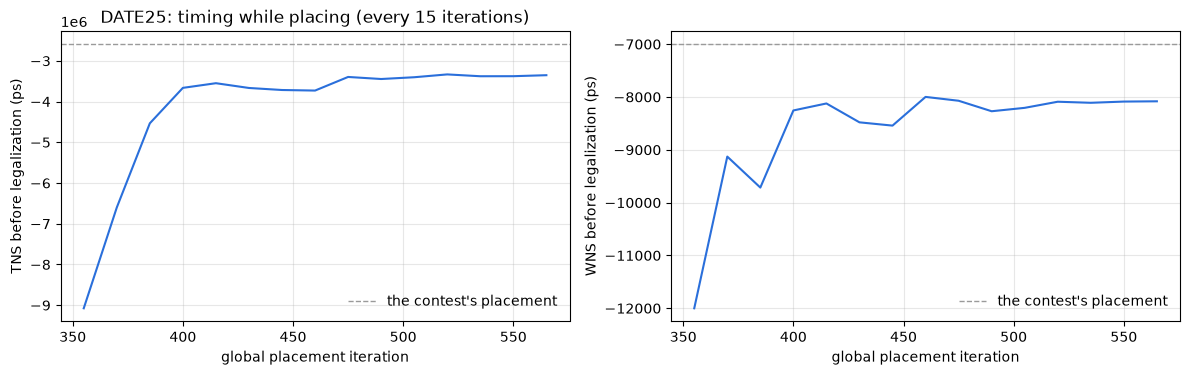

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot([r['it'] for r in trace], [r['tns'] for r in trace], color='#2a6fdb')
ax[1].plot([r['it'] for r in trace], [r['wns'] for r in trace], color='#2a6fdb')
for a_, ref in zip(ax, (sm['tns'], sm['wns'])):                # the contest's placement, for reference
    a_.axhline(ref, color='#9a9a9a', ls='--', lw=1, label="the contest's placement")
    a_.legend(frameon=False)
for a_, name in zip(ax, ('TNS', 'WNS')):
    a_.set_xlabel('global placement iteration'); a_.set_ylabel('%s before legalization (ps)' % name); a_.grid(alpha=.3)
ax[0].set_title('DATE25: timing while placing (every %d iterations)' % EVERY)
plt.tight_layout(); plt.show()

## Notes

* **Our runs** of this notebook's code (superblue18, seeds 0-2, RTX 4090): TNS -3.43e6 to -3.48e6 ps, WNS about
  -8.0e3 ps after legalization.
* **This is a port** of DATE25-TDP's pin-pair scheme to Attar's placer, not the original C++; timed by Attar, its
  results are on par with DATE25-TDP's own placements of the ICCAD 2015 designs.
* **Which timer.** Attar's timer equals OpenSTA (about 1 ps per endpoint on superblue). The papers and DREAMPlace
  report OpenTimer, which treats some input / output paths of these designs differently, so the absolute TNS here
  is larger and **not comparable with the papers' tables**.
* **Run to run.** GPU floating-point sums are not ordered, and timing feedback amplifies the difference, so a run
  with the same seed can end a few percent elsewhere. `naive.global_place(..., deterministic=True)` makes GPU runs
  repeatable (slower); try several seeds (`SEED`).